# ✅ OUTLIER HANDLING USING PERCENTILE METHOD (1% - 99%)
###### Dataset: weight-height.csv
###### Column Focus: Height
######
###### Strategy:
###### 1) Find lower_limit = 1st percentile (0.01)
###### 2) Find upper_limit = 99th percentile (0.99)
###### 3) TRIMMING  -> Remove rows outside limits
###### 4) CAPPING   -> Replace extreme values with limits (Winsorization)

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# -------------------------------
# Step 1) Load the dataset
# -------------------------------
df = pd.read_csv("weight-height.csv")

print("✅ Dataset Shape:", df.shape)
print("\n✅ First 5 rows:\n", df.head())

✅ Dataset Shape: (10000, 3)

✅ First 5 rows:
   Gender     Height      Weight
0   Male  73.847017  241.893563
1   Male  68.781904  162.310473
2   Male  74.110105  212.740856
3   Male  71.730978  220.042470
4   Male  69.881796  206.349801



✅ Height Summary:
 count    10000.000000
mean        66.367560
std          3.847528
min         54.263133
25%         63.505620
50%         66.318070
75%         69.174262
max         78.998742
Name: Height, dtype: float64


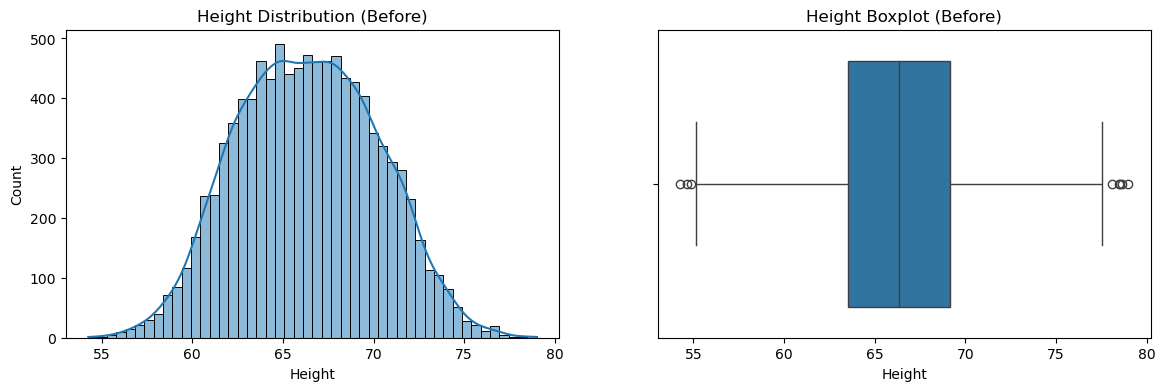

In [2]:
# Step 2) Basic statistics of Height
# -------------------------------
print("\n✅ Height Summary:\n", df["Height"].describe())

# -------------------------------
# Step 3) Visualize Height (Before Outlier Handling)
# -------------------------------
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
sns.histplot(df["Height"], kde=True)
plt.title("Height Distribution (Before)")

plt.subplot(1, 2, 2)
sns.boxplot(x=df["Height"])
plt.title("Height Boxplot (Before)")

plt.show()

In [3]:
# Step 4) Find percentile-based limits (1% and 99%)
# -------------------------------
upper_limit = df["Height"].quantile(0.99)
lower_limit = df["Height"].quantile(0.01)

print("\n✅ Percentile Limits:")
print("Lower Limit (1%) =", lower_limit)
print("Upper Limit (99%) =", upper_limit)


✅ Percentile Limits:
Lower Limit (1%) = 58.13441158671655
Upper Limit (99%) = 74.7857900583366


In [4]:
# Step 5) TRIMMING (Remove outlier rows)
# -------------------------------
new_df = df[(df["Height"] >= lower_limit) & (df["Height"] <= upper_limit)].copy()

print("\n✅ Shape after Trimming:", new_df.shape)
print("\n✅ Trimmed Height Summary:\n", new_df["Height"].describe())


✅ Shape after Trimming: (9800, 3)

✅ Trimmed Height Summary:
 count    9800.000000
mean       66.364366
std         3.645075
min        58.134496
25%        63.577162
50%        66.318070
75%        69.119896
max        74.785714
Name: Height, dtype: float64


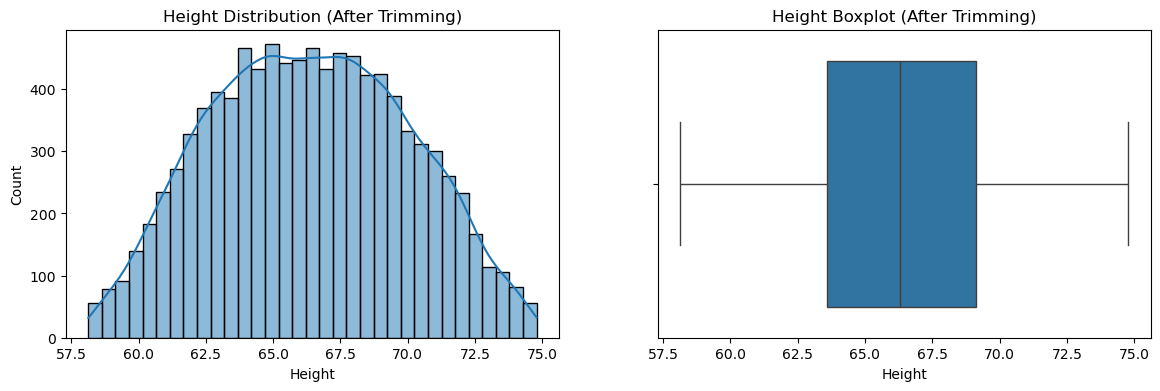

In [5]:
# Step 6) Visualize after Trimming
# -------------------------------
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
sns.histplot(new_df["Height"], kde=True)
plt.title("Height Distribution (After Trimming)")

plt.subplot(1, 2, 2)
sns.boxplot(x=new_df["Height"])
plt.title("Height Boxplot (After Trimming)")

plt.show()


In [6]:
# Step 7) CAPPING / WINSORIZATION
# Replace extreme values (outliers) with boundary values
# -------------------------------
df_cap = df.copy()

df_cap["Height"] = np.where(
    df_cap["Height"] > upper_limit,
    upper_limit,
    np.where(
        df_cap["Height"] < lower_limit,
        lower_limit,
        df_cap["Height"]
    )
)

print("\n✅ Shape after Capping:", df_cap.shape)
print("\n✅ Capped Height Summary:\n", df_cap["Height"].describe())


✅ Shape after Capping: (10000, 3)

✅ Capped Height Summary:
 count    10000.000000
mean        66.366281
std          3.795717
min         58.134412
25%         63.505620
50%         66.318070
75%         69.174262
max         74.785790
Name: Height, dtype: float64


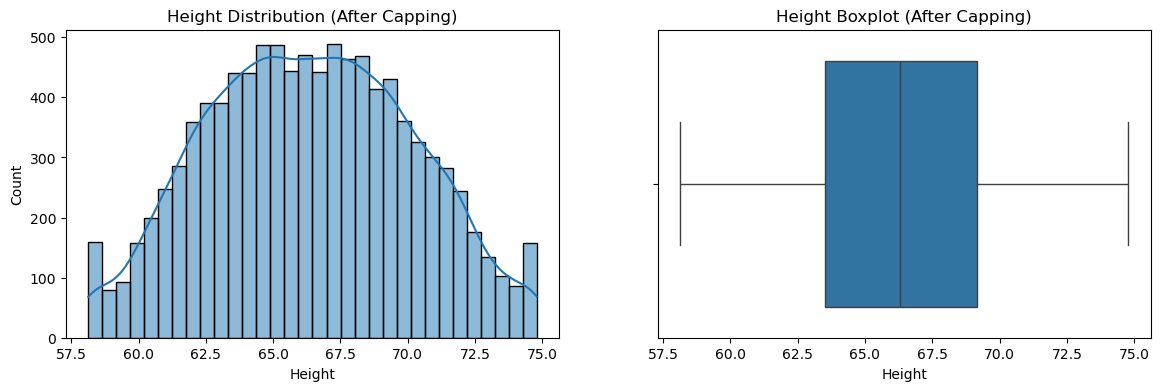

In [7]:
# Step 8) Visualize after Capping
# -------------------------------
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
sns.histplot(df_cap["Height"], kde=True)
plt.title("Height Distribution (After Capping)")

plt.subplot(1, 2, 2)
sns.boxplot(x=df_cap["Height"])
plt.title("Height Boxplot (After Capping)")

plt.show()